# Lab 1 — Intro to Behavioral TV Data
Name: Anna Zaporozhets | Group: KM-42

## Setup

In [9]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Panel and universe

In [10]:
# Count unique identifiers in the programs table
print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['program_name'].nunique())
print("Networks:", programs['network_code'].nunique())

# Filter households (H) and persons (R, L)
h_weights = daily_weights[daily_weights['resp_type'] == 'H']
p_weights = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]

print("Households in panel:", h_weights['respondent_id'].nunique())
print("Persons in panel:", p_weights['respondent_id'].nunique())

# Calculate total number of broadcast days in the month
n_days = daily_weights['broadcast_date'].nunique()

# Calculate average daily in-tab respondents
print("Households in-tab, average day:", f"{len(h_weights) / n_days:.2f}")
print("Persons in-tab, average day:", f"{len(p_weights) / n_days:.2f}")

# Project to US universe
h_rep_avg = h_weights.groupby('broadcast_date')['weight'].sum().mean() / 1_000_000
p_rep_avg = p_weights.groupby('broadcast_date')['weight'].sum().mean() / 1_000_000

print("US TV households represented, average day (M):", f"{h_rep_avg:.2f}")
print("US persons represented, average day (M):", f"{p_rep_avg:.2f}")
# Compare the roster with respondents measured at least once in October.
roster_h = viewer_details.loc[viewer_details['attr_id'] == 104, 'respondent_id'].nunique()
roster_p = viewer_details.loc[viewer_details['attr_id'].isin([101, 102]), 'respondent_id'].nunique()


Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.45
Persons in-tab, average day: 9268.68
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


**Answer:** The attribute roster contains 4256 households and 10216 persons, but only 4254 households and 10210 persons were in-tab at least once in October. The extra records were not measured on any October broadcast day; the data do not say whether they had left, had not yet joined, or were not measured for another reason.

## Task 1.2 — Average audience by hour of day

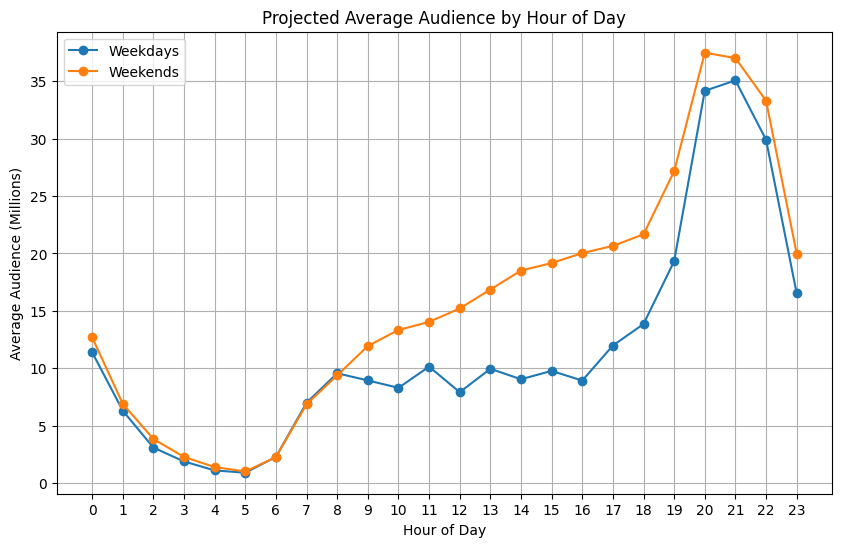

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [11]:
# Keep only persons (exclude households H and guests S)
v = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v['start_ts'] = pd.to_datetime(v['start_ts'])
v['end_ts'] = pd.to_datetime(v['end_ts'])

# A broadcast day starts at 06:00. Subtract 6 hours from start_ts
# to correctly assign overnight viewing to the previous broadcast day.
v['broadcast_date'] = (v['start_ts'] - pd.Timedelta(hours=6)).dt.date
v['is_weekend'] = pd.to_datetime(v['broadcast_date']).dt.dayofweek >= 5

# Split viewing sessions that cross hour boundaries
records = []
for row in v.itertuples(index=False):
    cur = row.start_ts
    end = row.end_ts

    while cur < end:
        next_hour = cur.ceil('h')
        if next_hour == cur:
            next_hour += pd.Timedelta(hours=1)

        step_end = min(end, next_hour)
        mins = (step_end - cur).total_seconds() / 60.0

        records.append({
            'hour': cur.hour,
            'is_weekend': (cur - pd.Timedelta(hours=6)).weekday() >= 5,
            'weighted_mins': mins * row.weight
        })
        cur = step_end

df_hours = pd.DataFrame(records)
hourly_sum = df_hours.groupby(['is_weekend', 'hour'])['weighted_mins'].sum().reset_index()

# Count the exact number of weekdays and weekends in the panel month
unique_dates = pd.to_datetime(daily_weights['broadcast_date'].unique())
n_we = (unique_dates.dayofweek >= 5).sum()
n_wd = (unique_dates.dayofweek < 5).sum()

# Calculate average audience in millions according to the hint formula
hourly_sum['audience_M'] = 0.0
wd_mask = hourly_sum['is_weekend'] == False
hourly_sum.loc[wd_mask, 'audience_M'] = hourly_sum.loc[wd_mask, 'weighted_mins'] / 60 / n_wd / 1_000_000

we_mask = hourly_sum['is_weekend'] == True
hourly_sum.loc[we_mask, 'audience_M'] = hourly_sum.loc[we_mask, 'weighted_mins'] / 60 / n_we / 1_000_000

weekdays = hourly_sum[~hourly_sum['is_weekend']].sort_values('hour')
weekends = hourly_sum[hourly_sum['is_weekend']].sort_values('hour')

# plot: projected average audience (M) by clock hour, weekday vs weekend
plt.figure(figsize=(10, 6))
plt.plot(weekdays['hour'], weekdays['audience_M'], label='Weekdays', marker='o')
plt.plot(weekends['hour'], weekends['audience_M'], label='Weekends', marker='o')
plt.title('Projected Average Audience by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(24))
plt.grid(True)
plt.legend()
plt.show()

# Find and print the peak hours
peak_wd = int(weekdays.loc[weekdays['audience_M'].idxmax(), 'hour'])
peak_we = int(weekends.loc[weekends['audience_M'].idxmax(), 'hour'])

print("Peak hour, weekdays:", peak_wd)
print("Peak hour, weekends:", peak_we)


**Answer:** Weekend viewing is higher during the day, while weekday viewing rises more strongly in the evening. The peak is at 21:00 on weekdays and 20:00 on weekends.

## Task 1.3 — Session length

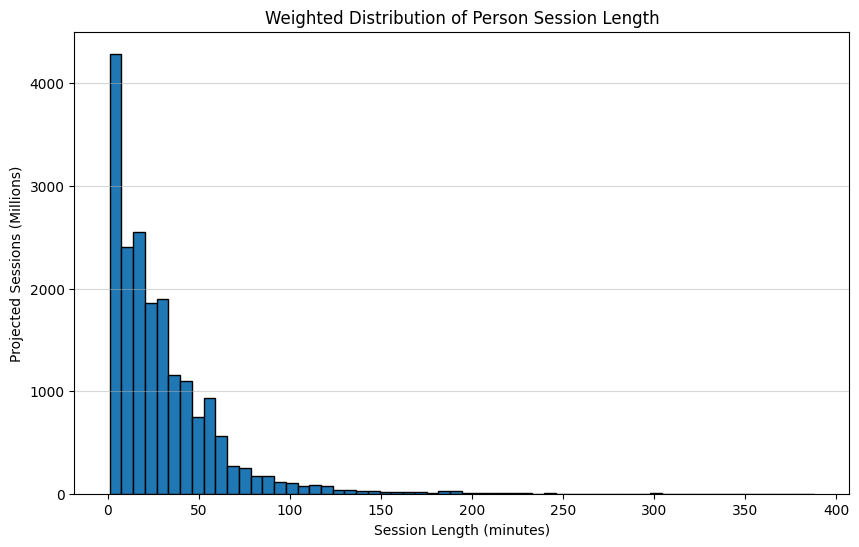

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


In [12]:
import numpy as np

# Filter for persons only (R, L)
v_len = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_len['start_ts'] = pd.to_datetime(v_len['start_ts'])
v_len['end_ts'] = pd.to_datetime(v_len['end_ts'])

# Calculate session duration in minutes
v_len['duration_min'] = (v_len['end_ts'] - v_len['start_ts']).dt.total_seconds() / 60.0
v_len = v_len[v_len['duration_min'] > 0]

# plot: weighted distribution of person session length
plt.figure(figsize=(10, 6))
plt.hist(v_len['duration_min'], bins=60, weights=v_len['weight'] / 1_000_000, edgecolor='black')
plt.title('Weighted Distribution of Person Session Length')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Projected Sessions (Millions)')
plt.grid(axis='y', alpha=0.5)
plt.show()

# Calculate weighted mean
weighted_mean = np.average(v_len['duration_min'], weights=v_len['weight'])

# Calculate weighted median (the point where cumulative weight reaches 50%)
v_sorted = v_len.sort_values('duration_min')
cumsum = v_sorted['weight'].cumsum()
cutoff = v_sorted['weight'].sum() / 2.0
weighted_median = v_sorted[cumsum >= cutoff]['duration_min'].iloc[0]

print("Session length, weighted mean (min):", round(weighted_mean, 2))
print("Session length, weighted median (min):", round(weighted_median, 2))

**Answer:** The mean is higher than the median because a small number of long sessions pull it up. I would show the median as the typical session length and use the histogram to show how much viewing varies.

## Task 2 — Program reach curve

,Date,HH Rating (%),P2+ Rating (%),Audience (M)
0,2024-10-01,3.5,1.7,5.28
1,2024-10-02,3.1,1.5,4.68
2,2024-10-03,3.0,1.5,4.68
3,2024-10-04,3.0,1.5,4.81
4,2024-10-07,3.1,1.5,4.83
5,2024-10-08,3.2,1.6,4.97
6,2024-10-09,3.0,1.5,4.70
7,2024-10-10,3.4,1.6,5.13
8,2024-10-11,3.1,1.5,4.69
9,2024-10-14,2.9,1.4,4.59


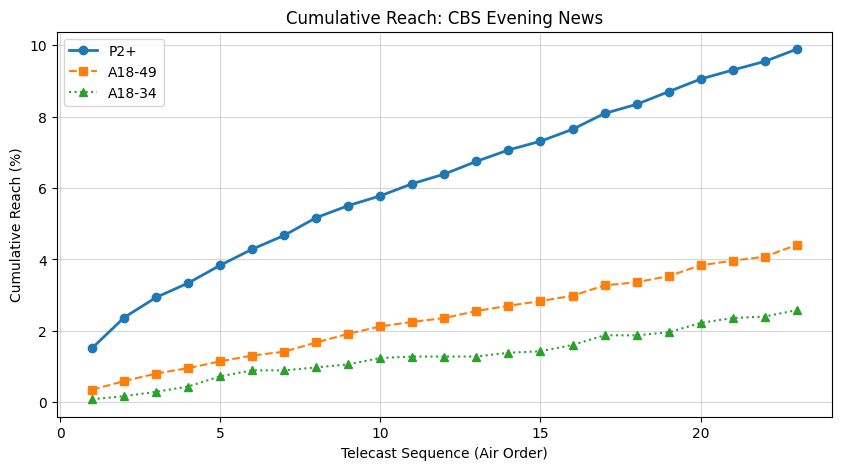

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [13]:
# 1. Prepare demographic and universe data
# Get exact age for each respondent
ages = viewer_details[viewer_details['attr_name'] == 'Age in years'].set_index('respondent_id')['value']

# Filter daily weights for Households (H) and Persons (R, L)
dw_h = daily_weights[daily_weights['resp_type'] == 'H']
dw_p2 = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
dw_p2['age'] = dw_p2['respondent_id'].map(ages)

# Calculate daily universe weights
univ_h_daily = dw_h.groupby(pd.to_datetime(dw_h['broadcast_date']).dt.normalize())['weight'].sum()
univ_p2_daily = dw_p2.groupby(pd.to_datetime(dw_p2['broadcast_date']).dt.normalize())['weight'].sum()

# Calculate average monthly weights per person
avg_w_p2 = dw_p2.groupby('respondent_id')['weight'].mean()
avg_w_1834 = dw_p2[(dw_p2['age'] >= 18) & (dw_p2['age'] <= 34)].groupby('respondent_id')['weight'].mean()
avg_w_1849 = dw_p2[(dw_p2['age'] >= 18) & (dw_p2['age'] <= 49)].groupby('respondent_id')['weight'].mean()

total_univ_p2 = avg_w_p2.sum()
total_univ_1834 = avg_w_1834.sum()
total_univ_1849 = avg_w_1849.sum()

# 2. Identify target telecasts
# Filter for 'CBS Evening News' on CBS network
cbs_news = programs[(programs['program_name'] == 'CBS Evening News') &
                    (programs['network_code'] == 'CBS')].copy()
cbs_news['start_ts'] = pd.to_datetime(cbs_news['start_ts'])
cbs_news['end_ts'] = pd.to_datetime(cbs_news['end_ts'])

# Sort by air time to get the correct chronological order
cbs_news = cbs_news.sort_values('start_ts').reset_index(drop=True)

# 3. Process viewings and calculate metrics
# Pre-filter viewings to CBS network to speed up calculations
cbs_v = viewings[(viewings['network_code'] == 'CBS') &
                 (viewings['resp_type'].isin(['H', 'R', 'L']))].copy()
cbs_v['start_ts'] = pd.to_datetime(cbs_v['start_ts'])
cbs_v['end_ts'] = pd.to_datetime(cbs_v['end_ts'])

telecast_results = []
cum_viewers_p2 = set()
cum_viewers_1834 = set()
cum_viewers_1849 = set()

reach_p2_hist = []
reach_1834_hist = []
reach_1849_hist = []

for idx, row in cbs_news.iterrows():
    t_start = row['start_ts']
    t_end = row['end_ts']
    b_date = pd.Timestamp(row['broadcast_date']).normalize()

    # Find viewings that overlap with the telecast time
    overlap = cbs_v[(cbs_v['end_ts'] > t_start) & (cbs_v['start_ts'] < t_end)].copy()
    overlap['o_start'] = overlap['start_ts'].clip(lower=t_start)
    overlap['o_end'] = overlap['end_ts'].clip(upper=t_end)
    overlap['mins'] = (overlap['o_end'] - overlap['o_start']).dt.total_seconds() / 60.0

    # Lab rule: count each respondent once after at least one minute.
    watched_minutes = overlap.groupby(['resp_type', 'respondent_id'])['mins'].sum()
    watched = watched_minutes[watched_minutes >= 1].reset_index()
    hh_ids = watched.loc[watched['resp_type'] == 'H', 'respondent_id']
    p2_ids = watched.loc[watched['resp_type'].isin(['R', 'L']), 'respondent_id'].tolist()

    # Use weights from the telecast's broadcast day, including nonviewers
    # in the universe denominator.
    day_weights = daily_weights.loc[
        pd.to_datetime(daily_weights['broadcast_date']).dt.normalize() == b_date
    ].set_index('respondent_id')['weight']
    hh_audience = day_weights.loc[hh_ids].sum()
    p2_audience = day_weights.loc[p2_ids].sum()

    telecast_results.append({
        'Date': b_date.date(),
        'HH Rating (%)': hh_audience / univ_h_daily.loc[b_date] * 100,
        'P2+ Rating (%)': p2_audience / univ_p2_daily.loc[b_date] * 100,
        'Audience (M)': p2_audience / 1_000_000
    })

    # Reach calculation (Cumulative)
    cum_viewers_p2.update(p2_ids)
    cum_viewers_1834.update([r for r in p2_ids if r in avg_w_1834.index])
    cum_viewers_1849.update([r for r in p2_ids if r in avg_w_1849.index])

    # Reach = sum of average weights of cumulative unique viewers / total average weights
    r_p2 = avg_w_p2.loc[list(cum_viewers_p2)].sum() / total_univ_p2 * 100
    r_1834 = avg_w_1834.loc[list(cum_viewers_1834)].sum() / total_univ_1834 * 100
    r_1849 = avg_w_1849.loc[list(cum_viewers_1849)].sum() / total_univ_1849 * 100

    reach_p2_hist.append(r_p2)
    reach_1834_hist.append(r_1834)
    reach_1849_hist.append(r_1849)

# table: household rating, P2+ rating, projected audience (M) per telecast
df_results = pd.DataFrame(telecast_results)
display(df_results.assign(**{
    'HH Rating (%)': df_results['HH Rating (%)'].map('{:.1f}'.format),
    'P2+ Rating (%)': df_results['P2+ Rating (%)'].map('{:.1f}'.format),
    'Audience (M)': df_results['Audience (M)'].map('{:.2f}'.format)
}))

# plot: cumulative reach P2+, A18-34, A18-49
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(reach_p2_hist) + 1), reach_p2_hist, label='P2+', marker='o', linewidth=2)
plt.plot(range(1, len(reach_1849_hist) + 1), reach_1849_hist, label='A18-49', marker='s', linestyle='--')
plt.plot(range(1, len(reach_1834_hist) + 1), reach_1834_hist, label='A18-34', marker='^', linestyle=':')
plt.title('Cumulative Reach: CBS Evening News')
plt.xlabel('Telecast Sequence (Air Order)')
plt.ylabel('Cumulative Reach (%)')
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

# Final printed metrics
print("Telecasts of the program:", len(df_results))
print("Average household rating (%):", f"{df_results['HH Rating (%)'].mean():.1f}")
print("Average P2+ rating (%):", f"{df_results['P2+ Rating (%)'].mean():.1f}")
print("Average projected audience (M):", f"{df_results['Audience (M)'].mean():.2f}")
print("Final reach P2+ (%):", f"{reach_p2_hist[-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach_1834_hist[-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach_1849_hist[-1]:.1f}")

**Answer:** Cumulative reach grows as new people watch on different days, even when each telecast reaches a similar share of the daily audience. P2+ has the highest reach, ahead of A18-49 and A18-34, which is consistent with network evening news attracting an older audience.

## Task 3 — Program frequency

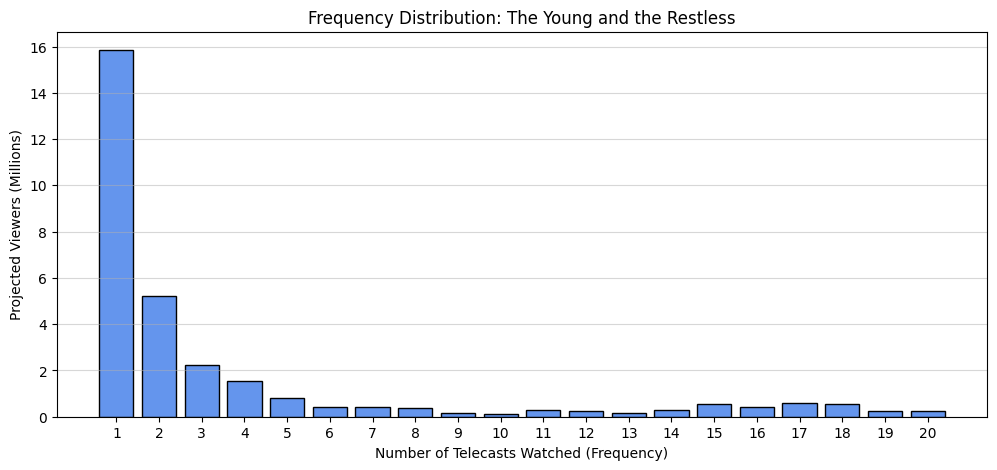

Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [14]:
# 1. Identify target telecasts
# Filter for 'The Young and the Restless' on CBS
yr_news = programs[(programs['program_name'] == 'The Young and the Restless') &
                   (programs['network_code'] == 'CBS')].copy()
yr_news['start_ts'] = pd.to_datetime(yr_news['start_ts'])
yr_news['end_ts'] = pd.to_datetime(yr_news['end_ts'])

# 2. Prepare viewings and monthly weights
# Get average monthly weights for all valid persons (R, L)
dw_p2 = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
monthly_weights = dw_p2.groupby('respondent_id')['weight'].mean()

# Filter viewings for CBS and valid persons to speed up overlap logic
yr_v = viewings[(viewings['network_code'] == 'CBS') &
                (viewings['resp_type'].isin(['R', 'L']))].copy()
yr_v['start_ts'] = pd.to_datetime(yr_v['start_ts'])
yr_v['end_ts'] = pd.to_datetime(yr_v['end_ts'])

# 3. Calculate frequency per respondent
viewed_telecasts = []

for idx, row in yr_news.iterrows():
    t_start = row['start_ts']
    t_end = row['end_ts']
    t_id = row['telecast_id']

    # Calculate overlap for the specific telecast
    overlap = yr_v[(yr_v['end_ts'] > t_start) & (yr_v['start_ts'] < t_end)].copy()
    overlap['o_start'] = overlap['start_ts'].clip(lower=t_start)
    overlap['o_end'] = overlap['end_ts'].clip(upper=t_end)
    overlap['mins'] = (overlap['o_end'] - overlap['o_start']).dt.total_seconds() / 60.0

    # Add separate sessions before applying the one-minute threshold.
    person_minutes = overlap.groupby('respondent_id')['mins'].sum()
    unique_viewers = person_minutes[person_minutes >= 1.0].index
    for uid in unique_viewers:
        viewed_telecasts.append({'respondent_id': uid, 'telecast_id': t_id})

# Convert to DataFrame and count unique telecasts per respondent
df_views = pd.DataFrame(viewed_telecasts)
if not df_views.empty:
    freq_df = df_views.groupby('respondent_id').size().reset_index(name='frequency')
else:
    freq_df = pd.DataFrame(columns=['respondent_id', 'frequency'])

# Merge frequency counts with average monthly weights
freq_df = freq_df.merge(monthly_weights.reset_index(), on='respondent_id', how='inner')

# 4. Calculate metrics
# Projected viewers in millions
proj_viewers_m = freq_df['weight'].sum() / 1_000_000

# Weighted average frequency
total_projected_views = (freq_df['frequency'] * freq_df['weight']).sum()
avg_freq = total_projected_views / freq_df['weight'].sum()

# Weighted median frequency
freq_df = freq_df.sort_values('frequency')
cumsum = freq_df['weight'].cumsum()
cutoff_50 = freq_df['weight'].sum() / 2.0
median_freq = freq_df[cumsum >= cutoff_50]['frequency'].iloc[0]

# 5. Loyalty: at or above the weighted 80th percentile, including ties
cutoff_80 = freq_df['weight'].sum() * 0.80
perc_80_freq = freq_df[cumsum >= cutoff_80]['frequency'].iloc[0]

loyal_mask = freq_df['frequency'] >= perc_80_freq
loyal_views = (freq_df.loc[loyal_mask, 'frequency'] * freq_df.loc[loyal_mask, 'weight']).sum()
share_loyal = loyal_views / total_projected_views

# 6. plot frequency distribution
# Group by frequency and sum the weights (in millions)
dist_df = freq_df.groupby('frequency')['weight'].sum() / 1_000_000

plt.figure(figsize=(12, 5))
plt.bar(dist_df.index, dist_df.values, color='cornflowerblue', edgecolor='black')
plt.title('Frequency Distribution: The Young and the Restless')
plt.xlabel('Number of Telecasts Watched (Frequency)')
plt.ylabel('Projected Viewers (Millions)')
plt.xticks(range(1, int(dist_df.index.max()) + 1))
plt.grid(axis='y', alpha=0.5)
plt.show()

# Final printed outputs matching template
print("Projected viewers (M):", f"{proj_viewers_m:.2f}")
print("Average frequency (weighted):", round(avg_freq, 2))
print("Median frequency (weighted):", round(median_freq, 2))
print("Share of views from the most loyal viewers:", f"{share_loyal:.3f}")


**Answer:** The weighted average is 3.63 telecasts, but the median is only 1, so the average alone hides the difference between occasional and regular viewers. The most loyal viewers watched at least 4 telecasts (the weighted 80th percentile, including everyone tied at the threshold) and account for 0.704 of projected views.

## Task 4 — Networks by age and gender

In [15]:
from IPython.display import display

# 1. Prepare respondent demographics
# Age is stored in value for attr_id 300.
# Sex is a flag: attr_id 201 = Male, attr_id 202 = Female.
ages = viewer_details[viewer_details['attr_name'] == 'Age in years'].set_index('respondent_id')['value']
genders = viewer_details[viewer_details['attr_group'] == 'Sex'].set_index('respondent_id')['attr_name']
genders = genders.map({'Male': 'M', 'Female': 'W'})

# Keep persons only (exclude households H and short-term guests S)
v_demo = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_demo['age'] = v_demo['respondent_id'].map(ages)
v_demo['gender'] = v_demo['respondent_id'].map(genders)

age_band = pd.cut(
    v_demo['age'], bins=[18, 35, 55, float('inf')],
    labels=['18-34', '35-54', '55+'], right=False
)
v_demo['demo_group'] = v_demo['gender'].astype('string') + age_band.astype('string')

# 2. Calculate raw and projected viewing minutes
# viewings already contains the correct daily weight for each session.
v_demo['start_ts'] = pd.to_datetime(v_demo['start_ts'])
v_demo['end_ts'] = pd.to_datetime(v_demo['end_ts'])
v_demo['raw_mins'] = (v_demo['end_ts'] - v_demo['start_ts']).dt.total_seconds() / 60.0
v_demo['proj_mins'] = v_demo['raw_mins'] * v_demo['weight']

# 3. Six top-5 tables by projected minutes
target_groups = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']
top5_tables = {}

for group in target_groups:
    group_data = v_demo[v_demo['demo_group'] == group]
    net_sums = group_data.groupby('network_code')['proj_mins'].sum()
    top5 = net_sums.sort_values(ascending=False).head(5)

    df_top5 = top5.to_frame('Projected minutes')
    df_top5.index.name = f'Network ({group})'
    top5_tables[group] = df_top5

    print(f'Top 5 networks: {group}')
    display(df_top5.assign(**{'Projected minutes': df_top5['Projected minutes'].map('{:.0f}'.format)}))

# 4. Share of each network's minutes coming from viewers aged 18-34
# The denominator includes all valid person viewers, including under-18s.
network_totals = v_demo.groupby('network_code').agg(
    total_proj_mins=('proj_mins', 'sum'),
    total_raw_mins=('raw_mins', 'sum')
)

young = v_demo[v_demo['age'].between(18, 34)]
network_young = young.groupby('network_code').agg(
    young_proj_mins=('proj_mins', 'sum'),
    young_raw_mins=('raw_mins', 'sum')
)

share_df = network_totals.join(network_young)
share_df[['young_proj_mins', 'young_raw_mins']] = share_df[['young_proj_mins', 'young_raw_mins']].fillna(0)

share_df['Weighted Share 18-34'] = (
    share_df['young_proj_mins'] / share_df['total_proj_mins'].where(share_df['total_proj_mins'] > 0)
)
share_df['Raw Share 18-34'] = (
    share_df['young_raw_mins'] / share_df['total_raw_mins'].where(share_df['total_raw_mins'] > 0)
)

final_share_table = share_df[['Weighted Share 18-34', 'Raw Share 18-34']].sort_values(
    by='Weighted Share 18-34', ascending=False
)

print('18-34 audience share by network:')
display(final_share_table.apply(lambda col: col.map('{:.3f}'.format)))

# Final printed outputs matching the template; rank before rounding.
youngest_net = final_share_table['Weighted Share 18-34'].idxmax()
oldest_net = final_share_table['Weighted Share 18-34'].idxmin()

print('Youngest network:', youngest_net)
print('Oldest network:', oldest_net)

Top 5 networks: M18-34


,Projected minutes
Network (M18-34),
FOX,4386649532
NBC,3910387623
CBS,3044349725
ABC,3010781207
FX,1473962615


Top 5 networks: W18-34


,Projected minutes
Network (W18-34),
FOX,4574440984
NBC,4527592683
ABC,3504858129
CBS,2811222042
FX,1383466392


Top 5 networks: M35-54


...

Top 5 networks: W55+


,Projected minutes
Network (W55+),
CBS,47120320973
NBC,41391868082
ABC,38840012626
FOX,36914718240
FNC,31450731770


18-34 audience share by network:


,Weighted Share 18-34,Raw Share 18-34
network_code,,
FX,0.266,0.232
BRAVO,0.148,0.127
FOX,0.082,0.075
FOOD,0.078,0.071
NBC,0.073,0.068
ABC,0.064,0.060
HGTV,0.058,0.052
CBS,0.051,0.050
HIST,0.048,0.044


Youngest network: FX
Oldest network: FNC


**Answer:** FX has the youngest audience by the 18-34 share of viewing minutes (0.266), and FNC has the oldest (0.018). Raw shares are lower on all ten networks, so young-adult viewing is underrepresented in raw panel minutes; using raw figures would understate this share and could mislead a client's network choice.

**Bonus answer:** FNC still delivers about 1.16 billion projected minutes from viewers aged 18-34 during the month. I would suggest checking which programmes and time slots attract them before choosing ad placements.